<a href="https://colab.research.google.com/github/buntyedutainer/allocation-optimizer/blob/main/Day06_Fair_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

So far we've compared our methods on a single dataset. That's risky, because one dataset can flatter one method by luck. Today we test all three methods on 30 different synthetic datasets and ask which differences are real and which could be luck.

Two ideas for today

Idea 1: one dataset can mislead. If a method wins once, that may be luck. If it wins on 30 different datasets, we can trust it much more. We report each result as an average plus a spread: the spread says how much the result changes from dataset to dataset.

Idea 2: compare on the same dataset, then look at the differences. For each dataset we subtract one method's result from the other's. If the difference is positive in almost every dataset, and the range where the true average difference probably lies stays on one side of zero, the difference is real. If that range includes zero, we can't claim one method is better. That range is called a 95% interval. We estimate it by reshuffling the 30 differences thousands of times to see how much their average wobbles.

In [1]:
# Cell 1: fetch your earlier files, and check matching.py has the optimal method
import os, subprocess
if not os.path.exists("scores.csv"):
    subprocess.run(["git", "clone", "-q", "https://github.com/buntyedutainer/allocation-optimizer", "repo"])
    subprocess.run("cp repo/data/*.csv .", shell=True)
    subprocess.run("cp repo/src/*.py .", shell=True)
print([f for f in ["scores.csv", "matching.py"] if os.path.exists(f)])
print("matching.py has the optimal method:", "def match_optimal" in open("matching.py").read())

['scores.csv', 'matching.py']
matching.py has the optimal method: True


Put the data generator into a file. On Day 2 the generator lived inside a notebook. Now it becomes a reusable tool, so we can build as many datasets as we like.

In [2]:
%%writefile datagen.py
"""Builds synthetic students, preferences and scores. The same seed always gives the same data."""
import numpy as np
import pandas as pd

SKILLS = ["Python", "Data analysis", "Web", "Design", "Writing", "Communication"]
RANK_POINTS = {1: 10, 2: 8, 3: 6, 4: 4, 5: 2}
W_PREF, W_FIT = 0.7, 0.3
UNLISTED_RANK = 6

PROJECTS = pd.DataFrame([
    ("P01", "Data Dashboard",        ["Data analysis", "Python"],               4, 0.9),
    ("P02", "Web Portal",            ["Web", "Design"],                         4, 0.5),
    ("P03", "Chatbot Helper",        ["Python", "Communication"],               3, 1.0),
    ("P04", "Learning Content",      ["Writing", "Design"],                     5, 0.3),
    ("P05", "Survey Analysis",       ["Data analysis", "Writing"],              5, 0.4),
    ("P06", "Mobile App",            ["Web", "Python"],                         3, 0.8),
    ("P07", "Community Outreach",    ["Communication", "Writing"],              6, 0.2),
    ("P08", "UX Research",           ["Design", "Communication"],               5, 0.5),
    ("P09", "Automation Scripts",    ["Python", "Data analysis"],               5, 0.6),
    ("P10", "Social Media Campaign", ["Writing", "Communication", "Design"],    4, 0.4),
], columns=["project_id", "title", "needs", "capacity", "appeal"]).set_index("project_id")


def make_students(n, rng):
    levels = rng.integers(0, 3, size=(n, len(SKILLS)))
    for i in range(n):
        strong = rng.choice(len(SKILLS), size=2, replace=False)
        levels[i, strong] = np.minimum(levels[i, strong] + 1, 3)
    ids = [f"S{i + 1:02d}" for i in range(n)]
    return pd.DataFrame(levels, index=ids, columns=SKILLS)


def fit_matrix(students, projects):
    fit = pd.DataFrame(index=students.index, columns=projects.index, dtype=float)
    for pid, row in projects.iterrows():
        fit[pid] = students[row["needs"]].mean(axis=1) / 3
    return fit


def make_preferences(fit, projects, rng, top_k=5):
    noise = rng.random(fit.shape)
    utility = 0.5 * projects["appeal"].values + 0.3 * fit.values + 0.2 * noise
    utility = pd.DataFrame(utility, index=fit.index, columns=fit.columns)
    rows = []
    for sid, u in utility.iterrows():
        best = u.sort_values(ascending=False).index[:top_k]
        for rank, pid in enumerate(best, start=1):
            rows.append((sid, pid, rank))
    return pd.DataFrame(rows, columns=["student_id", "project_id", "rank"])


def build_instance(seed, n_students=40):
    """One complete synthetic dataset: students, ranks, scores and capacities."""
    rng = np.random.default_rng(seed)
    students = make_students(n_students, rng)
    fit = fit_matrix(students, PROJECTS)
    prefs = make_preferences(fit, PROJECTS, rng)
    rank_table = (prefs.pivot(index="student_id", columns="project_id", values="rank")
                  .reindex(index=students.index, columns=PROJECTS.index).fillna(UNLISTED_RANK).astype(int))
    pref_points = rank_table.apply(lambda col: col.map(lambda r: RANK_POINTS.get(r, 0)))
    score = (W_PREF * pref_points + W_FIT * 10 * fit).round(2)
    return {"students": students, "score": score, "rank_table": rank_table,
            "capacity": PROJECTS["capacity"].copy()}

Writing datagen.py


Does the generator match our earlier data? Seed 42 built the data we've been using since Day 2, so the new generator should reproduce our Day 3 score table.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import datagen as D
import matching as M

inst = D.build_instance(42)
saved = pd.read_csv("scores.csv", index_col=0)
same = inst["score"].shape == saved.shape and np.allclose(inst["score"].values, saved.values, atol=0.01)
print("The generator reproduces your Day 3 score table:", same)

The generator reproduces your Day 3 score table: True


One function that tests every method on one dataset. Greedy and random depend on the line-up, so we try 20 random line-ups per dataset and use the average. The optimal method doesn't depend on the line-up, so it runs once.

In [4]:
METRICS = ["average happiness", "top-1 %", "top-3 %", "not on their list %", "worst rank", "lowest happiness"]

def evaluate_dataset(seed, n_lineups=20):
    inst = D.build_instance(seed)
    score, rank_table, capacity = inst["score"], inst["rank_table"], inst["capacity"]
    rng = np.random.default_rng(seed + 1000)
    rows = []

    opt = M.match_optimal(score, rank_table, capacity)
    rows.append({"seed": seed, "method": "Optimal", **M.summary(M.outcomes(opt, score, rank_table))})

    methods = [("Greedy", lambda order: M.match_greedy(score, rank_table, capacity, order)),
               ("Random", lambda order: M.match_random(score, rank_table, capacity, order, rng))]
    for name, fn in methods:
        runs = []
        for _ in range(n_lineups):
            order = list(rng.permutation(score.index))
            runs.append(M.summary(M.outcomes(fn(order), score, rank_table)))
        rows.append({"seed": seed, "method": name, **pd.DataFrame(runs).mean().to_dict()})
    return rows

print(pd.DataFrame(evaluate_dataset(100)).round(1))

   seed   method  average happiness  top-1 %  top-3 %  not on their list %  \
0   100  Optimal                5.7     25.0     52.5                 20.0   
1   100   Greedy                4.8     18.2     37.1                 26.4   
2   100   Random                4.1      8.2     29.6                 26.1   

   worst rank  lowest happiness  
0         6.0               1.5  
1         6.0               1.0  
2         6.0               0.4  


Run all 30 datasets. We use seeds 100 to 129, different from seed 42 which you've been studying. It's good practice not to judge methods on the data you built them with. This takes a minute or two.

In [5]:
SEEDS = list(range(100, 130))
all_rows, t0 = [], time.time()
for i, s in enumerate(SEEDS, 1):
    all_rows += evaluate_dataset(s)
    if i % 10 == 0:
        print(f"{i} of {len(SEEDS)} datasets done ({time.time() - t0:.0f} seconds)")
results = pd.DataFrame(all_rows)
print(results.shape, "(30 datasets x 3 methods = 90 rows)")

10 of 30 datasets done (11 seconds)
20 of 30 datasets done (21 seconds)
30 of 30 datasets done (32 seconds)
(90, 8) (30 datasets x 3 methods = 90 rows)


Average and spread.

In [6]:
def mean_sd(df):
    out = {}
    for m in METRICS:
        g = df.groupby("method")[m]
        out[m] = g.mean().round(1).astype(str) + " ± " + g.std().round(1).astype(str)
    return pd.DataFrame(out).loc[["Random", "Greedy", "Optimal"]]

print("Each cell: average over 30 datasets ± how much it varies from dataset to dataset")
mean_sd(results)

Each cell: average over 30 datasets ± how much it varies from dataset to dataset


,average happiness,top-1 %,top-3 %,not on their list %,worst rank,lowest happiness
method,,,,,,
Random,4.2 ± 0.1,8.6 ± 0.8,31.9 ± 2.1,20.1 ± 2.6,6.0 ± 0.0,0.4 ± 0.1
Greedy,4.9 ± 0.2,16.3 ± 2.2,42.3 ± 3.8,21.6 ± 3.0,6.0 ± 0.0,0.7 ± 0.2
Optimal,5.7 ± 0.2,22.9 ± 2.5,54.5 ± 5.2,10.8 ± 4.3,6.0 ± 0.0,1.5 ± 0.4


The paired comparison, Optimal minus Greedy on each dataset.

In [7]:
HIGHER_BETTER = {"average happiness": True, "top-1 %": True, "top-3 %": True,
                 "not on their list %": False, "worst rank": False, "lowest happiness": True}
wide = {m: results.pivot(index="seed", columns="method", values=m) for m in METRICS}

rng = np.random.default_rng(0)
rows = []
for m in METRICS:
    diff = wide[m]["Optimal"] - wide[m]["Greedy"]
    better = (diff > 1e-9) if HIGHER_BETTER[m] else (diff < -1e-9)
    tied = diff.abs() <= 1e-9
    wobble = [rng.choice(diff.values, len(diff)).mean() for _ in range(5000)]      # reshuffle the 30 differences
    lo, hi = np.percentile(wobble, [2.5, 97.5])
    rows.append({"metric": m,
                 "good direction": "higher" if HIGHER_BETTER[m] else "lower",
                 "average difference": round(diff.mean(), 2),
                 "95% interval": f"{lo:.2f} to {hi:.2f}",
                 "Optimal better in": f"{int(better.sum())} of {len(diff)}",
                 "tied": int(tied.sum()),
                 "clearly different?": "yes" if (lo > 0 or hi < 0) else "no"})
paired = pd.DataFrame(rows)
paired

,metric,good direction,average difference,95% interval,Optimal better in,tied,clearly different?
0,average happiness,higher,0.87,0.85 to 0.90,30 of 30,0,yes
1,top-1 %,higher,6.59,5.88 to 7.31,30 of 30,0,yes
2,top-3 %,higher,12.19,11.09 to 13.29,30 of 30,0,yes
3,not on their list %,lower,-10.77,-11.86 to -9.71,30 of 30,0,yes
4,worst rank,lower,0.00,0.00 to 0.00,0 of 30,30,no
5,lowest happiness,higher,0.76,0.62 to 0.90,29 of 30,0,yes


Look at it. Each dot is one dataset. A dot above the dashed line means Optimal scored higher than Greedy on that dataset.

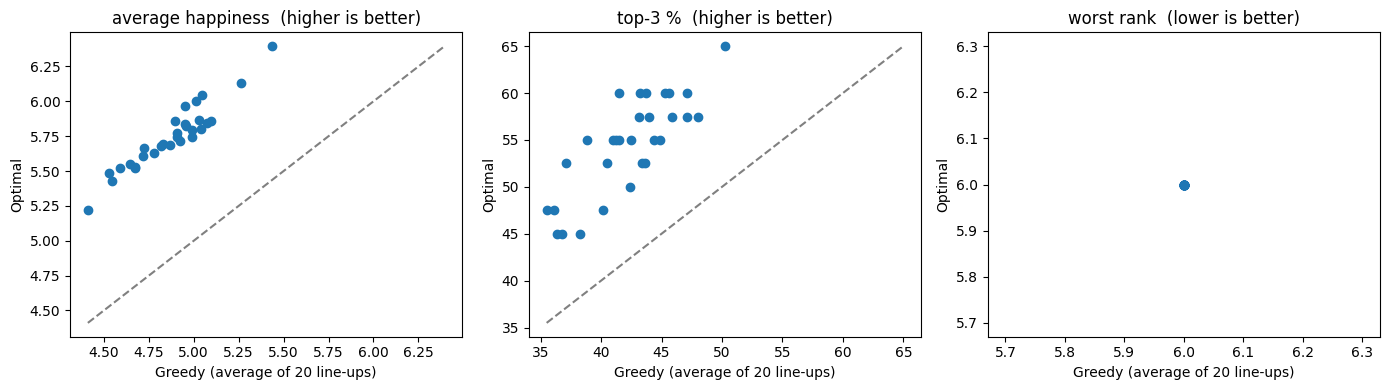

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, ["average happiness", "top-3 %", "worst rank"]):
    x, y = wide[m]["Greedy"], wide[m]["Optimal"]
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    ax.scatter(x, y)
    ax.plot([lo, hi], [lo, hi], "--", color="gray")
    ax.set_xlabel("Greedy (average of 20 line-ups)")
    ax.set_ylabel("Optimal")
    ax.set_title(m + ("  (higher is better)" if HIGHER_BETTER[m] else "  (lower is better)"))
plt.tight_layout()
plt.show()

What if you had only tried one dataset?

In [9]:
for m in ["average happiness", "top-3 %", "worst rank"]:
    d = wide[m]["Optimal"] - wide[m]["Greedy"]
    print(f"{m:18s} first dataset alone: {d.iloc[0]:+.2f} | across all 30: smallest {d.min():+.2f}, largest {d.max():+.2f}")

average happiness  first dataset alone: +0.86 | across all 30: smallest +0.75, largest +1.01
top-3 %            first dataset alone: +15.38 | across all 30: smallest +6.75, largest +18.50
worst rank         first dataset alone: +0.00 | across all 30: smallest +0.00, largest +0.00


Save

In [10]:
results.round(3).to_csv("comparison_30_datasets.csv", index=False)
paired.to_csv("paired_differences.csv", index=False)
print("Saved comparison_30_datasets.csv and paired_differences.csv")

Saved comparison_30_datasets.csv and paired_differences.csv
